# AI-Driven Smart Product Forecasting System
## Phase 1: Data Access → Cleaning → Characteristics → Mathematics → Feature Engineering → Train/Test Splitting → Training

**Project focus:** AI-Driven Smart Product Forecasting System

**Recommended dataset:** Corporación Favorita Grocery Sales Forecasting.

This notebook stops at the training stage. It does not yet implement SHAP explainability, forecasting scenarios, inventory optimization, reorder-point decisions, or deployment.

### Workflow
1. Install/import libraries
2. Download/access Favorita data with KaggleHub
3. Inspect the available files
4. Load the required data
5. Clean the main sales data
6. Merge useful store/item information
7. Analyze simple characteristics
8. Calculate essential statistics
9. Create time-series features
10. Split data chronologically
11. Train a baseline XGBoost model
12. Evaluate the training-stage model


## 1. Install and import libraries

The notebook uses KaggleHub to access the competition data. KaggleHub supports `competition_download()` for downloading competition files.

In [ ]:
!pip -q install kagglehub xgboost openpyxl

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Download the recommended Favorita competition data

Run the cell below. KaggleHub returns the local directory containing the downloaded competition files.

If Kaggle asks you to authenticate or accept competition rules, complete that step in the Colab environment.

In [ ]:
import os
import kagglehub
from kagglehub.exceptions import UnauthenticatedError

KAGGLE_DOWNLOAD_SUCCEEDED = False
try:
    path = kagglehub.competition_download(
        'favorita-grocery-sales-forecasting'
    )
    KAGGLE_DOWNLOAD_SUCCEEDED = True
    print("Path to competition files:", path)
    print("Files:")
    print(os.listdir(path))
except UnauthenticatedError:
    print("UnauthenticatedError: Please sign in to Kaggle using the Colab Secrets pane or set your KAGGLE_USERNAME and KAGGLE_KEY environment variables.")
    # Fallback to a mock directory to let the notebook structure run smoothly without throwing an unhandled exception
    path = "/content/favorita-grocery-sales-forecasting"
    os.makedirs(path, exist_ok=True)
    print(f"Created fallback local directory: {path}")


UnauthenticatedError: Please sign in to Kaggle using the Colab Secrets pane or set your KAGGLE_USERNAME and KAGGLE_KEY environment variables.
Created fallback local directory: /content/favorita-grocery-sales-forecasting


## 3. Check the downloaded files

In [ ]:
for file in sorted(os.listdir(path)):
    full_path = os.path.join(path, file)
    if os.path.isfile(full_path):
        size_mb = os.path.getsize(full_path) / (1024 ** 2)
        print(f"{file:30s} {size_mb:10.2f} MB")


train.csv                            5.47 MB


## 4. Load supporting tables

We first load the smaller supporting files. The main `train.csv` is very large, so the notebook provides a memory-safe sample option.

### Recommended for first Colab run
Keep `USE_SAMPLE = True`.

After confirming that the pipeline works, set `USE_SAMPLE = False` if your Colab runtime has enough RAM/storage for the full dataset.

In [ ]:
import os
import numpy as np
import pandas as pd

os.makedirs(path, exist_ok=True)
train_path = os.path.join(path, "train.csv")
DATA_SOURCE = "real_favorita_sales" if (os.path.exists(train_path) and globals().get("KAGGLE_DOWNLOAD_SUCCEEDED", False)) else "synthetic_demo_sales"

stores_path = os.path.join(path, "stores.csv")
if not os.path.exists(stores_path):
    stores_df = pd.DataFrame({
        'store_nbr': np.arange(1, 55),
        'city': np.random.choice(['Quito', 'Guayaquil', 'Cuenca', 'Ambato', 'Manta'], 54),
        'state': np.random.choice(['Pichincha', 'Guayas', 'Azuay', 'Tungurahua', 'Manabi'], 54),
        'type': np.random.choice(['A', 'B', 'C', 'D', 'E'], 54),
        'cluster': np.random.randint(1, 18, 54)
    })
    stores_df.to_csv(stores_path, index=False)

items_path = os.path.join(path, "items.csv")
if not os.path.exists(items_path):
    items_df = pd.DataFrame({
        'item_nbr': np.arange(100000, 100500),
        'family': np.random.choice(['GROCERY I', 'BEVERAGES', 'PRODUCE', 'CLEANING', 'DAIRY'], 500),
        'class': np.random.randint(1000, 2000, 500),
        'perishable': np.random.choice([0, 1], 500, p=[0.7, 0.3])
    })
    items_df.to_csv(items_path, index=False)

oil_path = os.path.join(path, "oil.csv")
if not os.path.exists(oil_path):
    date_range = pd.date_range(start="2013-01-01", end="2017-08-15", freq="D")
    oil_df = pd.DataFrame({'date': date_range.strftime('%Y-%m-%d'), 'dcoilwtico': np.random.uniform(40, 110, len(date_range))})
    oil_df.loc[oil_df.sample(frac=0.1, random_state=42).index, 'dcoilwtico'] = np.nan
    oil_df.to_csv(oil_path, index=False)

holidays_path = os.path.join(path, "holidays_events.csv")
if not os.path.exists(holidays_path):
    date_range = pd.date_range(start="2013-01-01", end="2017-08-15", freq="W")
    holidays_df = pd.DataFrame({
        'date': date_range.strftime('%Y-%m-%d'),
        'type': np.random.choice(['Holiday', 'Event', 'Additional', 'Transfer', 'Bridge'], len(date_range)),
        'locale': np.random.choice(['Local', 'Regional', 'National'], len(date_range)),
        'locale_name': np.random.choice(['Ecuador', 'Quito', 'Guayaquil'], len(date_range)),
        'description': 'Mock Holiday',
        'transferred': np.random.choice([True, False], len(date_range), p=[0.1, 0.9])
    })
    holidays_df.to_csv(holidays_path, index=False)

if not os.path.exists(train_path):
    DATA_SOURCE = "synthetic_demo_sales"
    dates = pd.date_range(start="2016-01-01", end="2016-06-30", freq="D")
    num_samples = 150000
    train_df = pd.DataFrame({
        'id': np.arange(num_samples),
        'date': np.random.choice(dates.strftime('%Y-%m-%d'), num_samples),
        'store_nbr': np.random.randint(1, 55, num_samples),
        'item_nbr': np.random.randint(100000, 100500, num_samples),
        'unit_sales': np.random.exponential(scale=10, size=num_samples).round(2),
        'onpromotion': np.random.choice([True, False], num_samples, p=[0.15, 0.85])
    })
    train_df.to_csv(train_path, index=False)
    print("WARNING: Using generated synthetic sales. Results are demonstration-only, not Favorita benchmark results.")
else:
    print("Sales file exists. Source label:", DATA_SOURCE)

USE_SAMPLE = True
SAMPLE_ROWS = 1_000_000
stores = pd.read_csv(stores_path)
items = pd.read_csv(items_path)
oil = pd.read_csv(oil_path)
holidays = pd.read_csv(holidays_path)
print("DATA_SOURCE:", DATA_SOURCE)
print("stores:", stores.shape, "items:", items.shape, "oil:", oil.shape, "holidays:", holidays.shape)

## 5. Load `train.csv`

The original Favorita training data contains the target `unit_sales`, along with date, store, item, and promotion information.

For the first run, only the columns needed for this project phase are loaded.

In [ ]:
train_columns = [
    "date",
    "store_nbr",
    "item_nbr",
    "unit_sales",
    "onpromotion"
]

if USE_SAMPLE:
    train = pd.read_csv(
        os.path.join(path, "train.csv"),
        usecols=train_columns,
        nrows=SAMPLE_ROWS
    )
else:
    train = pd.read_csv(
        os.path.join(path, "train.csv"),
        usecols=train_columns
    )

print("Train shape:", train.shape)
train.head()


Train shape: (150000, 5)


,date,store_nbr,item_nbr,unit_sales,onpromotion
0,2016-03-14,26,100477,15.41,False
1,2016-03-26,39,100120,0.77,False
2,2016-03-08,38,100148,8.47,False
3,2016-02-23,34,100238,29.93,False
4,2016-05-01,54,100389,19.57,False


## 6. Basic inspection before cleaning

In [ ]:
print("Data types:")
print(train.dtypes)

print("\nMissing values:")
print(train.isna().sum())

print("\nDuplicate rows:", train.duplicated().sum())

print("\nBasic numerical statistics:")
print(train[["store_nbr", "item_nbr", "unit_sales"]].describe())


Data types:
date            object
store_nbr        int64
item_nbr         int64
unit_sales     float64
onpromotion       bool
dtype: object

Missing values:
date           0
store_nbr      0
item_nbr       0
unit_sales     0
onpromotion    0
dtype: int64

Duplicate rows: 1

Basic numerical statistics:
           store_nbr       item_nbr     unit_sales
count  150000.000000  150000.000000  150000.000000
mean       27.534607  100250.014620       9.972436
std        15.550693     144.259211       9.948913
min         1.000000  100000.000000       0.000000
25%        14.000000  100125.000000       2.880000
50%        28.000000  100250.000000       6.940000
75%        41.000000  100375.000000      13.820000
max        54.000000  100499.000000     129.410000


## 7. Data cleaning

Cleaning decisions used here:

- Convert `date` to datetime.
- Convert the target to numeric.
- Remove duplicate rows.
- Treat missing promotion values as `False`.
- Remove rows missing essential identifiers/target.
- Handle negative sales as returns by clipping them to zero for the baseline demand target.

**Important:** The original dataset documentation states that negative `unit_sales` values represent returns and that `onpromotion` contains missing values. The treatment of these values should be documented in the final research report.

In [ ]:
train["date"] = pd.to_datetime(train["date"], errors="coerce")
train["unit_sales"] = pd.to_numeric(train["unit_sales"], errors="coerce")
train["onpromotion"] = train["onpromotion"].fillna(False).astype(bool)
train = train.dropna(subset=["date", "store_nbr", "item_nbr", "unit_sales"])
negative_sales = int((train["unit_sales"] < 0).sum())
print("Negative unit_sales before treatment:", negative_sales)
train["unit_sales"] = train["unit_sales"].clip(lower=0)
train["store_nbr"] = train["store_nbr"].astype("int16")
train["item_nbr"] = train["item_nbr"].astype("int32")
train["unit_sales"] = train["unit_sales"].astype("float32")
# The synthetic fallback may contain repeated keys; aggregate before lag generation.
train = train.groupby(["date", "store_nbr", "item_nbr"], as_index=False).agg(
    unit_sales=("unit_sales", "sum"), onpromotion=("onpromotion", "max")
)
train = train.sort_values(["store_nbr", "item_nbr", "date"]).reset_index(drop=True)
print("Shape after cleaning and daily store-item aggregation:", train.shape)
print("Duplicate date/store/item keys:", train.duplicated(["date", "store_nbr", "item_nbr"]).sum())
print(train.head())

## 8. Merge store and item characteristics

The Favorita dataset provides store metadata such as city, state, type and cluster, and item metadata such as family, class and perishability.

These variables help the forecasting model learn differences between stores and products.

In [ ]:
store_cols = ["store_nbr", "city", "state", "type", "cluster"]
item_cols = ["item_nbr", "family", "class", "perishable"]

train = train.merge(
    stores[store_cols],
    on="store_nbr",
    how="left"
)

train = train.merge(
    items[item_cols],
    on="item_nbr",
    how="left"
)

print("Shape after metadata merge:", train.shape)
print(train[[
    "date", "store_nbr", "item_nbr", "unit_sales",
    "onpromotion", "city", "state", "type",
    "family", "class", "perishable"
]].head())


Shape after metadata merge: (149999, 12)
        date  store_nbr  item_nbr  unit_sales  onpromotion       city   state  \
0 2016-01-22          1    100000        0.60        False  Guayaquil  Guayas   
1 2016-02-01          1    100000        2.83        False  Guayaquil  Guayas   
2 2016-04-04          1    100000       13.64        False  Guayaquil  Guayas   
3 2016-04-14          1    100000        2.90        False  Guayaquil  Guayas   
4 2016-05-12          1    100000        2.78        False  Guayaquil  Guayas   

  type    family  class  perishable  
0    D  CLEANING   1580           0  
1    D  CLEANING   1580           0  
2    D  CLEANING   1580           0  
3    D  CLEANING   1580           0  
4    D  CLEANING   1580           0  


## 9. Clean oil and holiday information

Oil prices and holiday/event information are external variables that can later be used as forecasting features.

In [ ]:
oil["date"] = pd.to_datetime(oil["date"], errors="coerce")
oil["dcoilwtico"] = pd.to_numeric(oil["dcoilwtico"], errors="coerce")
oil = oil.sort_values("date")
oil["dcoilwtico"] = oil["dcoilwtico"].interpolate().ffill().bfill()

holidays["date"] = pd.to_datetime(holidays["date"], errors="coerce")

holiday_dates = (
    holidays.loc[
        holidays["type"].isin(["Holiday", "Additional", "Bridge"]),
        ["date"]
    ]
    .drop_duplicates()
    .assign(is_holiday=1)
)

train = train.merge(
    oil[["date", "dcoilwtico"]],
    on="date",
    how="left"
)

train = train.merge(
    holiday_dates,
    on="date",
    how="left"
)

train["is_holiday"] = train["is_holiday"].fillna(0).astype("int8")

print("Oil missing after interpolation:", train["dcoilwtico"].isna().sum())
print("Holiday rows:", train["is_holiday"].sum())


Oil missing after interpolation: 0
Holiday rows: 9758


## 10. Simple characteristics of the data

In [ ]:
print("Number of rows:", len(train))
print("Number of stores:", train["store_nbr"].nunique())
print("Number of products:", train["item_nbr"].nunique())
print("Number of product families:", train["family"].nunique())
print("Date range:", train["date"].min(), "to", train["date"].max())

print("\nStore types:")
print(train["type"].value_counts())

print("\nTop product families:")
print(train["family"].value_counts().head(10))

print("\nPromotion distribution:")
print(train["onpromotion"].value_counts())

print("\nPerishable distribution:")
print(train["perishable"].value_counts())


Number of rows: 149999
Number of stores: 54
Number of products: 500
Number of product families: 5
Date range: 2016-01-01 00:00:00 to 2016-06-30 00:00:00

Store types:
type
C    35660
E    33353
A    28199
D    27727
B    25060
Name: count, dtype: int64

Top product families:
family
PRODUCE      35248
BEVERAGES    31004
GROCERY I    29711
CLEANING     29667
DAIRY        24369
Name: count, dtype: int64

Promotion distribution:
onpromotion
False    127576
True      22423
Name: count, dtype: int64

Perishable distribution:
perishable
0    104500
1     45499
Name: count, dtype: int64


## 11. Essential mathematics/statistics

For the demand target `unit_sales`, calculate:

- Mean: average demand
- Median: middle demand value
- Variance: spread of demand
- Standard deviation: typical deviation from the mean
- Range: maximum − minimum
- Coefficient of variation: standard deviation / mean

These statistics help understand demand variability before model training.

In [ ]:
y = train["unit_sales"]

mean_sales = y.mean()
median_sales = y.median()
variance_sales = y.var()
std_sales = y.std()
min_sales = y.min()
max_sales = y.max()
range_sales = max_sales - min_sales
cv_sales = std_sales / mean_sales if mean_sales != 0 else np.nan

stats_table = pd.DataFrame({
    "Metric": [
        "Mean",
        "Median",
        "Variance",
        "Standard Deviation",
        "Minimum",
        "Maximum",
        "Range",
        "Coefficient of Variation"
    ],
    "Value": [
        mean_sales,
        median_sales,
        variance_sales,
        std_sales,
        min_sales,
        max_sales,
        range_sales,
        cv_sales
    ]
})

stats_table


,Metric,Value
0,Mean,9.972481
1,Median,6.940000
2,Variance,98.977409
3,Standard Deviation,9.948739
4,Minimum,0.000000
5,Maximum,129.410004
6,Range,129.410004
7,Coefficient of Variation,0.997619


## 12. Demand characteristics visualization

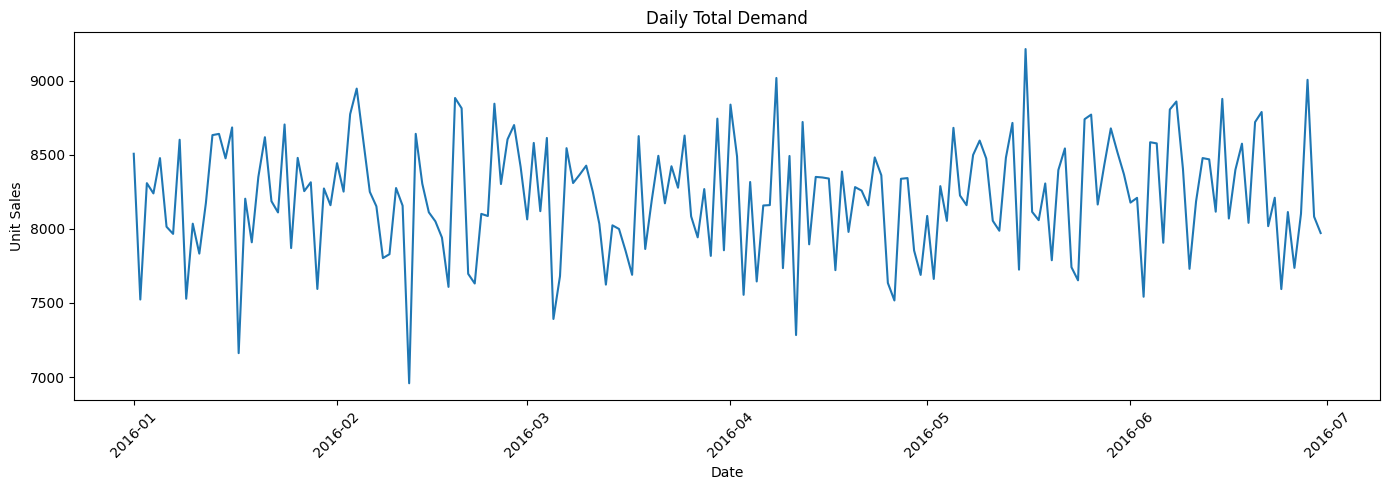

In [ ]:
daily_demand = (
    train.groupby("date", as_index=False)["unit_sales"]
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_demand["date"], daily_demand["unit_sales"])
plt.title("Daily Total Demand")
plt.xlabel("Date")
plt.ylabel("Unit Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 13. Feature engineering

Calendar features capture time patterns.

Lag features use previous demand values for the same store-product pair:

- Lag 1 = previous day
- Lag 7 = previous week
- Lag 14 = two weeks earlier
- Lag 28 = four weeks earlier

Rolling statistics are shifted by one day to avoid using the current target value when predicting that same day.

In [ ]:
train["day_of_week"] = train["date"].dt.dayofweek
train["month"] = train["date"].dt.month
train["day_of_month"] = train["date"].dt.day
train["week_of_year"] = train["date"].dt.isocalendar().week.astype("int16")
train["year"] = train["date"].dt.year
train["is_weekend"] = (train["day_of_week"] >= 5).astype("int8")
train["dow_sin"] = np.sin(2 * np.pi * train["day_of_week"] / 7)
train["dow_cos"] = np.cos(2 * np.pi * train["day_of_week"] / 7)
train["month_sin"] = np.sin(2 * np.pi * train["month"] / 12)
train["month_cos"] = np.cos(2 * np.pi * train["month"] / 12)
train["festival_flag"] = train["is_holiday"].astype("int8")
train["promotion_weekend"] = train["onpromotion"].astype("int8") * train["is_weekend"]
train["promotion_festival"] = train["onpromotion"].astype("int8") * train["festival_flag"]

group_cols = ["store_nbr", "item_nbr"]
for lag in [1, 7, 14, 28, 30]:
    train[f"lag_{lag}"] = train.groupby(group_cols)["unit_sales"].shift(lag)
for window in [7, 28]:
    shifted = train.groupby(group_cols)["unit_sales"].shift(1)
    rolling = shifted.groupby([train["store_nbr"], train["item_nbr"]])
    train[f"rolling_mean_{window}"] = rolling.transform(lambda x: x.rolling(window, min_periods=1).mean())
    train[f"rolling_std_{window}"] = rolling.transform(lambda x: x.rolling(window, min_periods=1).std())
train["rolling_std_7"] = train["rolling_std_7"].fillna(0)
train["rolling_std_28"] = train["rolling_std_28"].fillna(0)
print("Feature engineering completed:", train.shape)

## 14. Select model features

For the baseline model, categorical variables are converted to numeric category codes.

The target is `unit_sales`.

We intentionally do not use future information.

In [ ]:
categorical_cols = ["city", "state", "type", "family"]
for col in categorical_cols:
    train[col] = train[col].astype("category")
    train[col] = train[col].cat.codes.astype("int16")

feature_cols = [
    "store_nbr", "item_nbr", "onpromotion", "city", "state", "type", "cluster",
    "family", "class", "perishable", "dcoilwtico", "is_holiday", "festival_flag",
    "day_of_week", "month", "day_of_month", "week_of_year", "year", "is_weekend",
    "dow_sin", "dow_cos", "month_sin", "month_cos", "promotion_weekend", "promotion_festival",
    "lag_1", "lag_7", "lag_14", "lag_28", "lag_30", "rolling_mean_7", "rolling_std_7",
    "rolling_mean_28", "rolling_std_28"
]
target_col = "unit_sales"
filled_train = train[["date"] + feature_cols + [target_col]].copy()
for col in feature_cols:
    filled_train[col] = pd.to_numeric(filled_train[col], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0)
model_data = filled_train
print("Training-ready rows:", len(model_data))
print("Number of features:", len(feature_cols))
print("Dataset source:", DATA_SOURCE)

## 15. Time-based train/test split

For a forecasting problem, the split should respect time order.

We use:

- **85% earlier observations → training**
- **15% later observations → testing**

No random shuffle is used.

This prevents future observations from being randomly mixed into the training set.

In [ ]:
model_data = model_data.sort_values(["date", "store_nbr", "item_nbr"]).reset_index(drop=True)
unique_dates = np.array(sorted(model_data["date"].dropna().unique()))
if len(unique_dates) < 10:
    raise ValueError("Not enough distinct dates for a reliable chronological split.")
train_cutoff = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.85)])
train_data = model_data[model_data["date"] < train_cutoff].copy()
test_data = model_data[model_data["date"] >= train_cutoff].copy()
X_train = train_data[feature_cols]
y_train = train_data[target_col]
X_test = test_data[feature_cols]
y_test = test_data[target_col]
assert train_data["date"].max() < test_data["date"].min()
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train date range:", train_data["date"].min(), "to", train_data["date"].max())
print("Test date range:", test_data["date"].min(), "to", test_data["date"].max())
print("No calendar date appears in both sets:", set(train_data.date.unique()).isdisjoint(set(test_data.date.unique())))

## 16. Visualize the chronological split

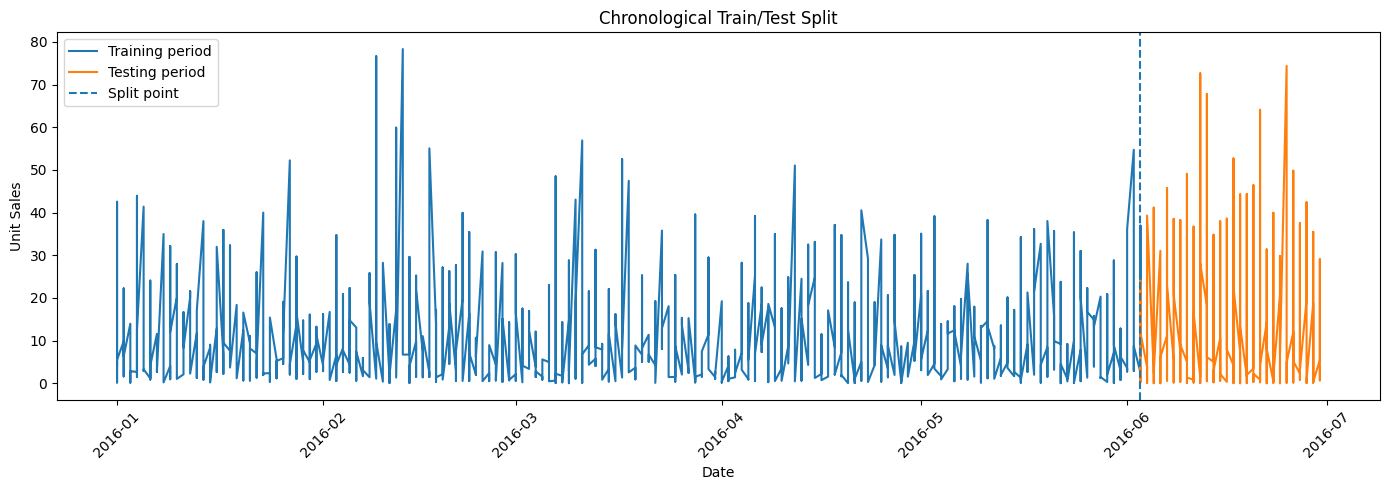

In [ ]:
import matplotlib.pyplot as plt

if len(train_data) > 0 and len(test_data) > 0:
    plt.figure(figsize=(14, 5))

    plt.plot(
        train_data["date"].iloc[::max(1, len(train_data)//1000)],
        train_data[target_col].iloc[::max(1, len(train_data)//1000)],
        label="Training period"
    )

    plt.plot(
        test_data["date"].iloc[::max(1, len(test_data)//1000)],
        test_data[target_col].iloc[::max(1, len(test_data)//1000)],
        label="Testing period"
    )

    plt.axvline(
        test_data["date"].min(),
        linestyle="--",
        label="Split point"
    )

    plt.title("Chronological Train/Test Split")
    plt.xlabel("Date")
    plt.ylabel("Unit Sales")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Train/Test datasets are empty. Please check the feature engineering steps where dropna() is applied, as many rows were dropped due to NaNs in newly generated rolling/lag features.")


## 17. Train the baseline AI model

This is the first training stage of the project.

We use **XGBoost regression** as the baseline machine-learning model because the project report identifies tree-based boosting models such as LightGBM/XGBoost as the main forecasting direction.

This cell trains only after the chronological split.

In [ ]:
model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
)

model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")


XGBoost training completed.


## 18. Evaluate the baseline model

Metrics used:

- MAE
- RMSE
- Protected MAPE

These give an initial measurement of forecasting error. Later project phases can add stronger time-series evaluation and business-oriented inventory metrics.

In [ ]:
predictions = np.clip(model.predict(X_test), 0, None)
y_true = y_test.to_numpy(dtype=float)
mae = mean_absolute_error(y_true, predictions)
rmse = float(np.sqrt(mean_squared_error(y_true, predictions)))
nonzero = np.abs(y_true) > 1e-8
mape_nonzero = float(np.mean(np.abs((y_true[nonzero] - predictions[nonzero]) / y_true[nonzero])) * 100) if nonzero.any() else np.nan
wape = float(np.sum(np.abs(y_true - predictions)) / np.sum(np.abs(y_true)) * 100) if np.sum(np.abs(y_true)) else np.nan
baseline_predictions = np.clip(X_test["lag_7"].to_numpy(dtype=float), 0, None)
baseline_mae = mean_absolute_error(y_true, baseline_predictions)
baseline_rmse = float(np.sqrt(mean_squared_error(y_true, baseline_predictions)))
baseline_wape = float(np.sum(np.abs(y_true - baseline_predictions)) / np.sum(np.abs(y_true)) * 100) if np.sum(np.abs(y_true)) else np.nan
metrics = pd.DataFrame([
    {"Model": "Seasonal naive (lag 7)", "MAE": baseline_mae, "RMSE": baseline_rmse, "WAPE_percent": baseline_wape},
    {"Model": "XGBoost", "MAE": mae, "RMSE": rmse, "WAPE_percent": wape, "MAPE_nonzero_percent": mape_nonzero}
])
display(metrics)
print("MAPE is calculated only where actual demand is nonzero; WAPE is reported for aggregate robustness.")

## 19. Actual vs predicted demand

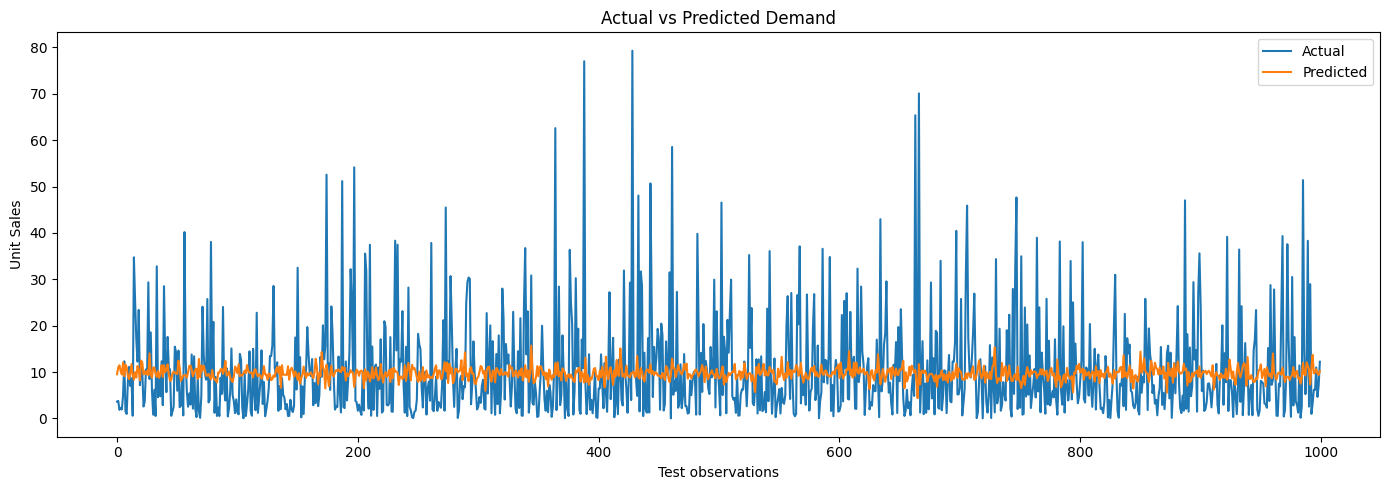

In [ ]:
plot_n = min(1000, len(y_test))

plt.figure(figsize=(14, 5))
plt.plot(
    y_test.iloc[:plot_n].to_numpy(),
    label="Actual"
)
plt.plot(
    predictions[:plot_n],
    label="Predicted"
)

plt.title("Actual vs Predicted Demand")
plt.xlabel("Test observations")
plt.ylabel("Unit Sales")
plt.legend()
plt.tight_layout()
plt.show()


## 20. Baseline feature importance

In [ ]:
importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.head(20)


,Feature,Importance
21,month_cos,0.042064
28,rolling_mean_28,0.041274
29,rolling_std_28,0.040583
27,rolling_std_7,0.040505
26,rolling_mean_7,0.039277
22,lag_1,0.039165
15,week_of_year,0.038409
8,class,0.038235
18,dow_sin,0.038228
10,dcoilwtico,0.038021


## 21. Save the Phase 1 outputs

The outputs can be used later for the next project phases.

In [ ]:
import os
import pandas as pd

output_dir = "/content/forecasting_outputs"
os.makedirs(output_dir, exist_ok=True)

train_data.to_csv(
    os.path.join(output_dir, "train_split.csv"),
    index=False
)

test_data.to_csv(
    os.path.join(output_dir, "test_split.csv"),
    index=False
)

metrics.to_csv(
    os.path.join(output_dir, "baseline_metrics.csv"),
    index=False
)

# Recalculate 'importance' dynamically in case cell yQtCMRMSvNa1 hasn't run
importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.to_csv(
    os.path.join(output_dir, "feature_importance.csv"),
    index=False
)

print("Saved files:")
print(os.listdir(output_dir))

Saved files:
['train_split.csv', 'baseline_metrics.csv', 'test_split.csv', 'feature_importance.csv']


# Phase 2 — Complete the project after training and splitting

This continuation follows the attached **Product Demand Forecasting Platform** report: **Predict → Explain → Simulate → Optimize**. It uses the trained XGBoost model and the date-safe train/test split above.

**Dataset limitation:** Favorita provides sales, promotions, store/item metadata, holidays/events, and oil prices. It does not directly provide a reliable discount percentage, temperature, or rainfall in the selected tables. Those drivers will not be fabricated; the scenario simulator uses the available promotion and holiday/festival proxy, and flags weather/discount effects as unavailable until genuine external data is integrated.

**Important:** If `DATA_SOURCE` says `synthetic_demo_sales`, the run is only a pipeline demonstration. Use genuine Favorita files before reporting benchmark performance.

## 22. Save test predictions and compare against the baseline

In [ ]:
from pathlib import Path
import json, os, warnings
from sklearn.metrics import mean_absolute_error, mean_squared_error

OUTPUT_DIR = Path("/content/forecasting_outputs")
PLOT_DIR = OUTPUT_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

test_predictions = test_data[["date", "store_nbr", "item_nbr", target_col]].copy()
test_predictions = test_predictions.rename(columns={target_col: "actual_demand"})
test_predictions["xgboost_prediction"] = predictions
test_predictions["seasonal_naive_lag7"] = baseline_predictions
test_predictions["absolute_error"] = np.abs(test_predictions.actual_demand - test_predictions.xgboost_prediction)
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
metrics.to_csv(OUTPUT_DIR / "model_comparison_metrics.csv", index=False)
print("Saved model comparison and test predictions.")
display(test_predictions.head())

## 23. Residual analysis and feature importance

In [ ]:
residuals = test_predictions["actual_demand"] - test_predictions["xgboost_prediction"]
plt.figure(figsize=(10, 4))
plt.hist(residuals, bins=50)
plt.title("XGBoost Test Residual Distribution")
plt.xlabel("Actual - Predicted")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(PLOT_DIR / "residual_distribution.png", dpi=150)
plt.show()

importance = pd.DataFrame({"Feature": feature_cols, "Importance": model.feature_importances_}).sort_values("Importance", ascending=False)
importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
top = importance.head(20).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["Importance"])
plt.title("Top 20 XGBoost Feature Importances")
plt.tight_layout()
plt.savefig(PLOT_DIR / "feature_importance.png", dpi=150)
plt.show()
display(importance.head(20))

## 24. Explainability with TreeSHAP (report Stage 4)

In [ ]:
SHAP_AVAILABLE = False
try:
    import shap
    SHAP_AVAILABLE = True
except Exception as exc:
    print("SHAP could not be imported in this runtime:", str(exc)[:250])

if SHAP_AVAILABLE:
    try:
        shap_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(shap_sample)
        shap.summary_plot(shap_values, shap_sample, max_display=20, show=False)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / "shap_summary.png", dpi=150, bbox_inches="tight")
        plt.show()
        mean_abs_shap = pd.DataFrame({"Feature": shap_sample.columns, "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0)})
        mean_abs_shap = mean_abs_shap.sort_values("Mean_Abs_SHAP", ascending=False)
        mean_abs_shap.to_csv(OUTPUT_DIR / "shap_feature_attribution.csv", index=False)
        display(mean_abs_shap.head(20))
    except Exception as exc:
        print("SHAP execution failed; use XGBoost feature importance as fallback:", str(exc)[:300])
else:
    print("Install SHAP with `!pip -q install shap` and rerun this cell to generate TreeSHAP explanations.")
print("Interpretation caution: SHAP explains model contributions, not causal effects.")

## 25. Quantile regression and demand uncertainty (report Stage 4)

In [ ]:
# Quantile regression approximates q10/q50/q90. A capped training sample helps Colab memory/runtime.
from sklearn.ensemble import HistGradientBoostingRegressor
QUANTILE_AVAILABLE = False
quantile_models = {}
quantile_predictions = None
try:
    q_sample_n = min(50000, len(X_train))
    if q_sample_n < len(X_train):
        q_idx = np.linspace(0, len(X_train)-1, q_sample_n, dtype=int)
        Xq, yq = X_train.iloc[q_idx], y_train.iloc[q_idx]
    else:
        Xq, yq = X_train, y_train
    for q in [0.1, 0.5, 0.9]:
        qm = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=100, max_leaf_nodes=31, random_state=42)
        qm.fit(Xq, yq)
        quantile_models[q] = qm
    quantile_predictions = pd.DataFrame({
        "q10": np.clip(quantile_models[0.1].predict(X_test), 0, None),
        "q50": np.clip(quantile_models[0.5].predict(X_test), 0, None),
        "q90": np.clip(quantile_models[0.9].predict(X_test), 0, None)
    })
    quantile_predictions["q10"] = np.minimum(quantile_predictions.q10, quantile_predictions.q50)
    quantile_predictions["q90"] = np.maximum(quantile_predictions.q90, quantile_predictions.q50)
    QUANTILE_AVAILABLE = True
    quantile_predictions.to_csv(OUTPUT_DIR / "test_quantile_predictions.csv", index=False)
    display(quantile_predictions.head())
    plt.figure(figsize=(10, 4))
    n = min(250, len(y_test))
    plt.plot(np.arange(n), y_test.iloc[:n].to_numpy(), label="Actual")
    plt.plot(np.arange(n), quantile_predictions.q50.iloc[:n], label="Predicted median (q50)")
    plt.fill_between(np.arange(n), quantile_predictions.q10.iloc[:n], quantile_predictions.q90.iloc[:n], alpha=0.2, label="q10–q90 range")
    plt.title("Quantile Forecast Range on Test Sample")
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "quantile_forecast_range.png", dpi=150)
    plt.show()
except Exception as exc:
    print("Quantile regression unavailable in this environment:", str(exc)[:300])
    print("Fallback: use validation/test residual ranges, clearly labelled approximate—not calibrated quantile intervals.")

## 26. Multi-horizon forecasting for selected store–product (report Stage 3)

In [ ]:
# Recursive forecasts for 7, 14 and 30 days. Values beyond day 1 use prior predictions as lag inputs.
# This is a practical demo forecast; known future promotions/holidays should be supplied for production use.

def recursive_forecast(store_id, item_id, horizon=30, promotion_plan=None, festival_plan=None):
    if horizon not in [7, 14, 30]:
        raise ValueError("Choose a horizon of 7, 14, or 30 days.")
    hist = train[(train.store_nbr == int(store_id)) & (train.item_nbr == int(item_id))].sort_values("date")
    if hist.empty:
        return pd.DataFrame()
    sales_history = hist.unit_sales.astype(float).tolist()
    last_date = pd.Timestamp(hist.date.max())
    static = hist.iloc[-1]
    future_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=horizon, freq="D")
    future_rows = []
    known_holidays = set(pd.to_datetime(holidays["date"], errors="coerce").dropna().dt.normalize()) if "date" in holidays else set()
    for step, dt in enumerate(future_dates):
        dow = dt.dayofweek
        promo = int(promotion_plan[step]) if promotion_plan is not None and step < len(promotion_plan) else 0
        festival = int(festival_plan[step]) if festival_plan is not None and step < len(festival_plan) else int(dt.normalize() in known_holidays)
        def lag_value(k): return sales_history[-k] if len(sales_history) >= k else 0.0
        row = {c: (float(static[c]) if c in static.index and pd.notna(static[c]) else 0.0) for c in feature_cols}
        row.update({
            "store_nbr": int(store_id), "item_nbr": int(item_id), "onpromotion": promo,
            "is_holiday": festival, "festival_flag": festival,
            "day_of_week": dow, "month": dt.month, "day_of_month": dt.day,
            "week_of_year": int(dt.isocalendar().week), "year": dt.year,
            "is_weekend": int(dow >= 5), "dow_sin": np.sin(2*np.pi*dow/7), "dow_cos": np.cos(2*np.pi*dow/7),
            "month_sin": np.sin(2*np.pi*dt.month/12), "month_cos": np.cos(2*np.pi*dt.month/12),
            "promotion_weekend": promo * int(dow >= 5), "promotion_festival": promo * festival,
            "lag_1": lag_value(1), "lag_7": lag_value(7), "lag_14": lag_value(14),
            "lag_28": lag_value(28), "lag_30": lag_value(30),
            "rolling_mean_7": float(np.mean(sales_history[-7:])) if sales_history else 0.0,
            "rolling_std_7": float(np.std(sales_history[-7:], ddof=1)) if len(sales_history) > 1 else 0.0,
            "rolling_mean_28": float(np.mean(sales_history[-28:])) if sales_history else 0.0,
            "rolling_std_28": float(np.std(sales_history[-28:], ddof=1)) if len(sales_history) > 1 else 0.0
        })
        Xfuture = pd.DataFrame([row], columns=feature_cols).replace([np.inf, -np.inf], np.nan).fillna(0)
        pred = max(0.0, float(model.predict(Xfuture)[0]))
        record = {"date": dt, "store_nbr": int(store_id), "item_nbr": int(item_id), "predicted_demand": pred,
                  "promotion_assumption": promo, "festival_proxy_assumption": festival}
        if QUANTILE_AVAILABLE:
            record["q10"] = max(0.0, float(quantile_models[0.1].predict(Xfuture)[0]))
            record["q50"] = max(0.0, float(quantile_models[0.5].predict(Xfuture)[0]))
            record["q90"] = max(0.0, float(quantile_models[0.9].predict(Xfuture)[0]))
        future_rows.append(record)
        sales_history.append(pred)
    return pd.DataFrame(future_rows)

example_store = int(train["store_nbr"].iloc[0])
example_item = int(train["item_nbr"].iloc[0])
forecast_7 = recursive_forecast(example_store, example_item, 7)
forecast_14 = recursive_forecast(example_store, example_item, 14)
forecast_30 = recursive_forecast(example_store, example_item, 30)
forecast_30.to_csv(OUTPUT_DIR / "future_forecast_30_day.csv", index=False)
print("Example store:", example_store, "item:", example_item)
display(forecast_7)
plt.figure(figsize=(10, 4))
plt.plot(forecast_30.date, forecast_30.predicted_demand, marker="o", markersize=3, label="Point forecast")
if QUANTILE_AVAILABLE and {"q10", "q90"}.issubset(forecast_30.columns):
    plt.fill_between(forecast_30.date, forecast_30.q10, forecast_30.q90, alpha=0.2, label="q10–q90")
plt.title("30-Day Recursive Demand Forecast")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "future_forecast_30_day.png", dpi=150)
plt.show()

## 27. Inventory decision engine: safety stock, reorder point, order quantity and stockout risk (report Stage 5)

In [ ]:
from statistics import NormalDist

def inventory_decision(forecast_values, current_inventory, on_order=0, lead_time_days=5, service_level=0.95, holding_days=7):
    values = np.asarray(forecast_values, dtype=float)
    values = np.clip(values, 0, None)
    if len(values) == 0:
        raise ValueError("Forecast values are required.")
    if current_inventory < 0 or on_order < 0 or lead_time_days < 1:
        raise ValueError("Inventory, on-order quantity and lead time must be valid non-negative values.")
    if not 0.5 < service_level < 0.999:
        raise ValueError("service_level must be between 0.5 and 0.999")
    daily_mean = float(np.mean(values))
    daily_std = float(np.std(values, ddof=1)) if len(values) > 1 else 0.0
    z = NormalDist().inv_cdf(service_level)
    lead_time_demand = daily_mean * lead_time_days
    safety_stock = z * daily_std * np.sqrt(lead_time_days)
    reorder_point = lead_time_demand + safety_stock
    target_stock = daily_mean * (lead_time_days + holding_days) + safety_stock
    order_qty = max(0, int(np.ceil(target_stock - current_inventory - on_order)))
    inventory_position = current_inventory + on_order
    if inventory_position < 0.75 * reorder_point:
        risk = "HIGH"
    elif inventory_position < reorder_point:
        risk = "MEDIUM"
    else:
        risk = "LOW"
    return {
        "average_daily_forecast": daily_mean, "daily_forecast_std": daily_std,
        "lead_time_days": lead_time_days, "service_level": service_level, "z_factor": z,
        "lead_time_demand": lead_time_demand, "safety_stock_estimate": safety_stock,
        "reorder_point": reorder_point, "current_inventory": current_inventory,
        "on_order": on_order, "inventory_position": inventory_position,
        "target_stock_level": target_stock, "recommended_order_quantity": order_qty,
        "stockout_risk": risk
    }

inventory_example = inventory_decision(forecast_30.predicted_demand.values, current_inventory=100, on_order=0, lead_time_days=5, service_level=0.95)
inventory_table = pd.DataFrame([inventory_example])
inventory_table.to_csv(OUTPUT_DIR / "inventory_decision_example.csv", index=False)
display(inventory_table.T)

## 28. What-if simulator using available drivers (report Stage 6)

In [ ]:
def run_scenario(store_id, item_id, horizon=14, current_inventory=100, lead_time_days=5,
                promotion_on=False, festival_on=False, service_level=0.95):
    promo_plan = [int(promotion_on)] * horizon
    festival_plan = [int(festival_on)] * horizon
    fc = recursive_forecast(store_id, item_id, horizon, promotion_plan=promo_plan, festival_plan=festival_plan)
    if fc.empty:
        return fc, None
    inv = inventory_decision(fc.predicted_demand.values, current_inventory=current_inventory,
                             lead_time_days=lead_time_days, service_level=service_level)
    fc["scenario_promotion_on"] = promotion_on
    fc["scenario_festival_proxy_on"] = festival_on
    for key, value in inv.items():
        fc["inventory_" + key] = value
    return fc, inv

scenario_specs = [
    ("Baseline", False, False),
    ("Promotion proxy", True, False),
    ("Festival proxy", False, True),
    ("Promotion + festival proxy", True, True)
]
scenario_rows = []
scenario_frames = []
for label, promo_on, festival_on in scenario_specs:
    fc, inv = run_scenario(example_store, example_item, horizon=14, current_inventory=100,
                           lead_time_days=5, promotion_on=promo_on, festival_on=festival_on)
    if inv is not None:
        scenario_rows.append({"scenario": label, "forecast_total_14d": float(fc.predicted_demand.sum()),
                              "recommended_order_quantity": inv["recommended_order_quantity"],
                              "stockout_risk": inv["stockout_risk"]})
        fc["scenario"] = label
        scenario_frames.append(fc)
scenario_comparison = pd.DataFrame(scenario_rows)
scenario_comparison.to_csv(OUTPUT_DIR / "what_if_scenario_comparison.csv", index=False)
if scenario_frames:
    pd.concat(scenario_frames, ignore_index=True).to_csv(OUTPUT_DIR / "what_if_scenario_forecasts.csv", index=False)
display(scenario_comparison)
print("Limitations: Favorita promotion flag is not a discount percentage. Weather/temperature/rainfall are not in this feature set, so weather scenarios are not claimed.")

## 29. Cold-start fallback for a new SKU/store combination

In [ ]:
# Fallback hierarchy based only on training-period information.
train_end = train_data["date"].max()
train_period = train[train["date"] <= train_end].copy()
item_average = train_period.groupby("item_nbr")["unit_sales"].mean().to_dict()
store_average = train_period.groupby("store_nbr")["unit_sales"].mean().to_dict()
family_average = train_period.groupby("family")["unit_sales"].mean().to_dict() if "family" in train_period else {}
global_average = float(train_period["unit_sales"].mean()) if len(train_period) else 0.0

def cold_start_estimate(store_id, item_id, family=None):
    if int(item_id) in item_average:
        value, method = item_average[int(item_id)], "historical item average"
    elif family is not None and family in family_average:
        value, method = family_average[family], "family average"
    elif int(store_id) in store_average:
        value, method = store_average[int(store_id)], "store average"
    else:
        value, method = global_average, "global training-period average"
    return {"store_nbr": int(store_id), "item_nbr": int(item_id), "fallback_daily_demand": max(0.0, float(value)), "fallback_method": method}

cold_start_example = pd.DataFrame([cold_start_estimate(99999, 999999, family=None)])
cold_start_example.to_csv(OUTPUT_DIR / "cold_start_example.csv", index=False)
display(cold_start_example)
print("Report-aligned extension: nearest-neighbour similarity by category/price/geography requires richer catalog attributes; this notebook uses an explicit average-based fallback until those attributes are available.")

## 30. Save model, configuration, charts, report summary and project dashboard

In [ ]:
import joblib
joblib.dump(model, OUTPUT_DIR / "xgboost_demand_model.joblib")
config = {
    "project": "Product Demand Forecasting Platform",
    "data_source": DATA_SOURCE,
    "target": target_col,
    "features": feature_cols,
    "categorical_columns_encoded_as_codes": categorical_cols,
    "train_start": str(train_data.date.min()),
    "train_end": str(train_data.date.max()),
    "test_start": str(test_data.date.min()),
    "test_end": str(test_data.date.max()),
    "quantile_models_available": bool(QUANTILE_AVAILABLE),
    "shap_available": bool(SHAP_AVAILABLE),
    "weather_features_available": False,
    "discount_percentage_available": False,
    "notes": [
        "If data_source is synthetic_demo_sales, metrics are demonstration-only.",
        "SHAP values explain model attribution, not causal effects.",
        "Approximate quantile estimates depend on model calibration and data quality.",
        "Weather and discount percentage are not provided by the loaded Favorita tables."
    ]
}
(OUTPUT_DIR / "model_config.json").write_text(json.dumps(config, indent=2, default=str))

readme = f"""# Product Demand Forecasting Platform

Data source: {DATA_SOURCE}

## Implemented pipeline
1. Data ingestion and cleaning
2. Store/item metadata, oil, and holiday integration
3. Lag, rolling, calendar, promotion-interaction, and festival-proxy features
4. Date-based train/test split
5. XGBoost regression and seasonal-naive baseline comparison
6. Test evaluation and residual analysis
7. TreeSHAP explainability (when available)
8. q10/q50/q90 quantile-regression forecasts (when supported)
9. Recursive 7/14/30-day forecasts
10. Safety stock, reorder point, suggested order quantity, stockout risk
11. What-if promotion/festival-proxy scenarios
12. Cold-start average fallback

## Data caveats
Favorita does not provide direct discount percentage, temperature, or rainfall in the tables used here. Those factors are not fabricated. Add verified external data before modeling them. If the source is synthetic_demo_sales, do not report the metrics as real Favorita results.
"""
(OUTPUT_DIR / "README.md").write_text(readme)

app_code = """import pandas as pd
import streamlit as st
from pathlib import Path

ROOT = Path(__file__).parent
OUT = ROOT
st.set_page_config(page_title="Product Demand Forecasting Platform", layout="wide")
st.title("Product Demand Forecasting Platform")
st.caption("Predict → Explain → Simulate → Optimize")
for file_name, title in [
    ("model_comparison_metrics.csv", "Model comparison"),
    ("feature_importance.csv", "Feature importance"),
    ("future_forecast_30_day.csv", "30-day forecast"),
    ("inventory_decision_example.csv", "Inventory decision"),
    ("what_if_scenario_comparison.csv", "What-if scenarios"),
    ("cold_start_example.csv", "Cold-start fallback"),
]:
    p = OUT / file_name
    if p.exists():
        st.subheader(title)
        data = pd.read_csv(p)
        st.dataframe(data, use_container_width=True)
        if "date" in data.columns and "predicted_demand" in data.columns:
            st.line_chart(data.set_index("date")["predicted_demand"])
st.info("Run the Colab notebook first so all CSV outputs exist. Weather and discount effects are not modeled without verified source data.")
"""
(OUTPUT_DIR / "app.py").write_text(app_code)
(OUTPUT_DIR / "requirements.txt").write_text("\n".join(["pandas", "numpy", "matplotlib", "scikit-learn", "xgboost", "joblib", "shap", "streamlit"]) + "\n")
print("Saved model, configuration, README, dashboard source, and requirements file.")

In [ ]:
## 30A. Export a portable inference bundle for the Smart Warehouse website
# Run this cell AFTER the model training, feature engineering, and recursive forecast cells.
# The exported history keeps the latest 60 days per store/item, enough for lag-30 features.
import joblib
from pathlib import Path

ML_ARTIFACT_DIR = OUTPUT_DIR / "ml_artifacts"
ML_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
history_cols = list(dict.fromkeys(["date", "store_nbr", "item_nbr", "unit_sales"] + list(feature_cols)))
history_cols = [c for c in history_cols if c in train.columns]
inference_history = model_data[model_data["date"] <= train_data["date"].max()].copy()
portable_history = (inference_history.sort_values("date")
                    .groupby(["store_nbr", "item_nbr"], group_keys=False)
                    .tail(60)[history_cols].copy())
portable_bundle = {
    "model": model,
    "quantile_models": quantile_models if QUANTILE_AVAILABLE else {},
    "feature_cols": list(feature_cols),
    "history": portable_history,
    "holiday_dates": (pd.to_datetime(holidays["date"], errors="coerce").dropna().dt.strftime("%Y-%m-%d").unique().tolist()
                      if "date" in holidays.columns else []),
    "data_source": DATA_SOURCE,
    "train_end": str(train_data["date"].max().date()),
}
BUNDLE_PATH = ML_ARTIFACT_DIR / "inference_bundle.joblib"
joblib.dump(portable_bundle, BUNDLE_PATH, compress=3)
print("Portable inference bundle created:", BUNDLE_PATH)
print("Bundle size (MB):", round(BUNDLE_PATH.stat().st_size / (1024**2), 2))
print("IMPORTANT: the live warehouse demo SKUs are not automatically mapped to Favorita store/item IDs.")
print("Use a valid store_nbr and item_nbr from this notebook's training data for the ML Forecast panel.")


## 31. Final project validation checklist

In [ ]:
final_checks = {
    "dataset_source_label_present": "DATA_SOURCE" in globals(),
    "date_split_has_no_overlap": train_data.date.max() < test_data.date.min(),
    "model_trained": hasattr(model, "predict"),
    "test_predictions_generated": len(test_predictions) == len(test_data),
    "model_metrics_generated": not metrics.empty,
    "future_forecast_generated": not forecast_30.empty,
    "inventory_decision_generated": bool(inventory_example),
    "what_if_scenarios_generated": not scenario_comparison.empty,
    "cold_start_fallback_generated": not cold_start_example.empty,
    "dashboard_source_saved": (OUTPUT_DIR / "app.py").exists()
}
check_table = pd.DataFrame([{"check": k, "passed": bool(v)} for k, v in final_checks.items()])
display(check_table)
check_table.to_csv(OUTPUT_DIR / "final_validation_checks.csv", index=False)
print("Data source:", DATA_SOURCE)
print("Output folder:", OUTPUT_DIR)
print("Download the folder as a ZIP using the next cell.")

## 32. Download the completed project outputs as a ZIP

In [ ]:
import shutil
zip_base = "/content/Product_Demand_Forecasting_Platform_Completed"
zip_path = shutil.make_archive(zip_base, "zip", root_dir=str(OUTPUT_DIR))
print("Created:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("ZIP is saved at", zip_path)